# Assignment 3, Task 4: Quantitative analysis

Data: `results.csv` from Task 3 (one row per participant and question).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

In [2]:
# Evaluation data from Task 3
path = '../evaluation/results.csv' if os.path.exists('../evaluation/results.csv') else 'results.csv'
res = pd.read_csv(path)
out_dir = '../results_figures'; os.makedirs(out_dir, exist_ok=True)
colors = {'Static':'#8c8c8c', 'Interactive':'#2b6cb0'}
order = ['Static','Interactive']
res.head()

,participant_id,group,task,variant,condition,correct,time_s,timed_out,first_condition,struggles
0,P01,1,T1,A,Static,1,50,no,Static,Figuring out axis for static
1,P01,1,T1,B,Interactive,1,43,no,Static,Figuring out axis for static
2,P01,1,T2,A,Static,1,32,no,Static,Figuring out axis for static
3,P01,1,T2,B,Interactive,1,43,no,Static,Figuring out axis for static
4,P02,2,T1,B,Static,1,37,no,Static,Understanding the Question 2B


In [3]:
# 4.0 Data check: participants, rows per participant, participants per group, timeouts
print(res.participant_id.nunique(), 'participants,', len(res), 'rows')
print(res.groupby('participant_id').size().unique(), 'rows per participant')
print(res.groupby('group').participant_id.nunique().to_dict(), 'participants per group')
print(res.timed_out.value_counts().to_dict(), 'timed out')

10 participants, 40 rows
[4] rows per participant
{1: 3, 2: 2, 3: 3, 4: 2} participants per group
{'no': 40} timed out


**Descriptive statistics**

In [4]:
# 4.1 Accuracy and time per condition
def summary(g):
    return pd.Series({'n': len(g), 'correct': g.correct.sum(), 'accuracy %': round(100*g.correct.mean(),1),
                      'mean time (s)': round(g.time_s.mean(),1), 'median time (s)': g.time_s.median(),
                      'SD (s)': round(g.time_s.std(),1), 'min (s)': g.time_s.min(), 'max (s)': g.time_s.max()})
by_cond = res.groupby('condition').apply(summary).loc[order]
by_cond

,n,correct,accuracy %,mean time (s),median time (s),SD (s),min (s),max (s)
condition,,,,,,,,
Static,20.0,16.0,80.0,36.4,30.5,14.5,21.0,69.0
Interactive,20.0,20.0,100.0,33.4,30.5,13.2,16.0,75.0


In [5]:
# 4.2 Per task and variant
by_task = res.groupby(['task','variant','condition']).apply(summary)[['n','correct','accuracy %','mean time (s)','median time (s)']]
by_task

n  correct  accuracy %  mean time (s)  \
task variant condition                                              
T1   A       Interactive  4.0      4.0       100.0           47.8   
             Static       6.0      6.0       100.0           38.0   
     B       Interactive  6.0      6.0       100.0           27.5   
             Static       4.0      4.0       100.0           43.0   
T2   A       Interactive  4.0      4.0       100.0           35.5   
             Static       6.0      2.0        33.3           28.0   
     B       Interactive  6.0      6.0       100.0           28.5   
             Static       4.0      4.0       100.0           39.8   

                          median time (s)  
task variant condition                     
T1   A       Interactive             42.0  
             Static                  37.0  
     B       Interactive             23.5  
             Static                  41.0  
T2   A       Interactive             38.0  
             Static                  27.5  
     B       Interactive             27.0  
             Static                  34.5

In [6]:
# 4.3 Per task (both variants together)
res.groupby(['task','condition']).apply(summary)[['n','correct','accuracy %','mean time (s)','median time (s)']]

n  correct  accuracy %  mean time (s)  median time (s)
task condition                                                             
T1   Interactive  10.0     10.0       100.0           35.6             34.0
     Static       10.0     10.0       100.0           40.0             41.0
T2   Interactive  10.0     10.0       100.0           31.3             29.0
     Static       10.0      6.0        60.0           32.7             28.5

**Visualizations**

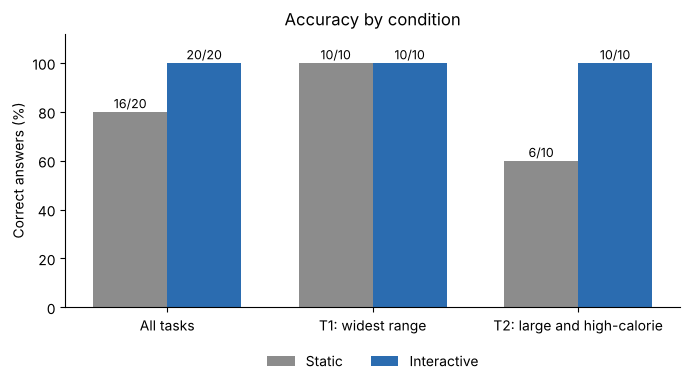

In [7]:
# 4.4 Accuracy: percent correct per condition, overall and per task (labels show correct / total)
fig, ax = plt.subplots(figsize=(7,4))
groups = [('All tasks', res), ('T1: widest range', res[res.task=='T1']), ('T2: large and high-calorie', res[res.task=='T2'])]
w = 0.36
for j, cond in enumerate(order):
    for i, (name, g) in enumerate(groups):
        s = g[g.condition==cond]
        ax.bar(i + (j-0.5)*w, 100*s.correct.mean(), w, color=colors[cond], label=cond if i==0 else None)
        ax.text(i + (j-0.5)*w, 100*s.correct.mean()+1.5, f'{s.correct.sum()}/{len(s)}', ha='center', fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels([n for n,_ in groups])
ax.set_ylim(0,112); ax.set_ylabel('Correct answers (%)'); ax.set_title('Accuracy by condition')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5,-0.12), ncol=2); sns.despine()
plt.tight_layout(); plt.savefig(out_dir + '/fig_accuracy.png', dpi=200); plt.show()

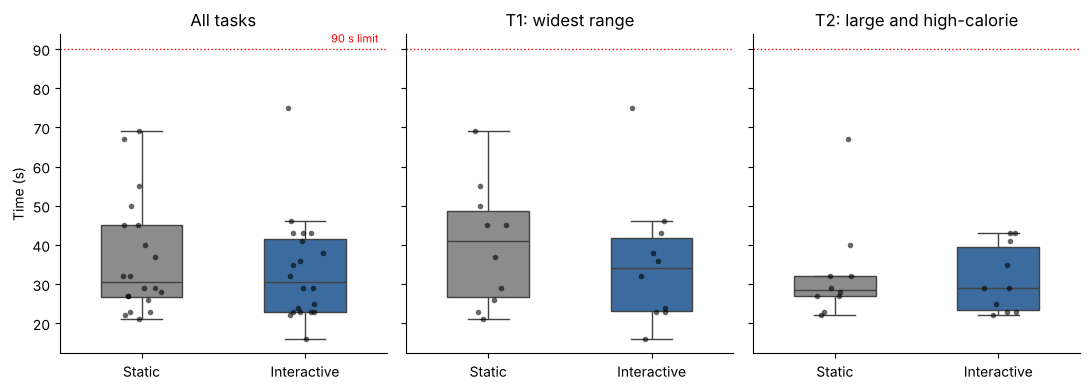

In [8]:
# 4.5 Completion time: distribution per condition and task (each dot is one question)
fig, axes = plt.subplots(1, 3, figsize=(11,4), sharey=True)
for ax, (name, g) in zip(axes, [('All tasks', res), ('T1: widest range', res[res.task=='T1']), ('T2: large and high-calorie', res[res.task=='T2'])]):
    sns.boxplot(data=g, x='condition', y='time_s', order=order, hue='condition', palette=colors, legend=False, width=0.5, fliersize=0, ax=ax)
    sns.stripplot(data=g, x='condition', y='time_s', order=order, color='black', size=4, alpha=0.6, jitter=0.12, ax=ax)
    ax.set_title(name); ax.set_xlabel(''); ax.set_ylabel('Time (s)')
    ax.axhline(90, color='red', ls=':', lw=1)
axes[0].text(1.45, 91, '90 s limit', color='red', fontsize=8, ha='right', va='bottom')
sns.despine(); plt.tight_layout(); plt.savefig(out_dir + '/fig_time.png', dpi=200); plt.show()

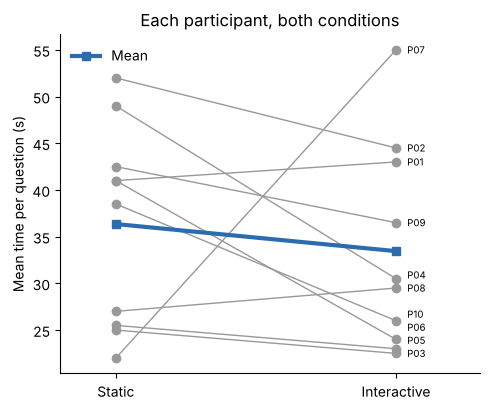

In [9]:
# 4.6 Participants: mean time per participant, static vs interactive (each line is one person)
pt = res.pivot_table(index='participant_id', columns='condition', values='time_s', aggfunc='mean')[order]
pa = res.pivot_table(index='participant_id', columns='condition', values='correct', aggfunc='sum')[order]
fig, ax = plt.subplots(figsize=(5,4.2))
ys = {}; last = -99
for pid, v in pt['Interactive'].sort_values().items():
    last = max(v, last + 1.4); ys[pid] = last
for pid, row in pt.iterrows():
    ax.plot([0,1], row.values, color='#999999', marker='o', lw=1)
    ax.text(1.04, ys[pid], pid, fontsize=7, va='center')
ax.plot([0,1], pt.mean().values, color='#2b6cb0', marker='s', lw=3, label='Mean')
ax.set_xticks([0,1]); ax.set_xticklabels(order); ax.set_xlim(-0.2,1.3)
ax.set_ylabel('Mean time per question (s)'); ax.set_title('Each participant, both conditions')
ax.legend(frameon=False); sns.despine(); plt.tight_layout(); plt.savefig(out_dir + '/fig_participants.png', dpi=200); plt.show()

**Comparison across participants, tasks and order**

In [10]:
# 4.7 Per participant: difference in mean time (static minus interactive) and correct answers out of 2 per condition
cmp_p = pd.DataFrame({'static time': pt['Static'].round(1), 'interactive time': pt['Interactive'].round(1),
                      'static minus interactive (s)': (pt['Static']-pt['Interactive']).round(1),
                      'static correct /2': pa['Static'], 'interactive correct /2': pa['Interactive']})
print((pt['Static'] > pt['Interactive']).sum(), 'of', len(pt), 'participants were faster with interactive')
cmp_p

7 of 10 participants were faster with interactive


,static time,interactive time,static minus interactive (s),static correct /2,interactive correct /2
participant_id,,,,,
P01,41.0,43.0,-2.0,2,2
P02,52.0,44.5,7.5,2,2
P03,25.0,22.5,2.5,1,2
P04,49.0,30.5,18.5,2,2
P05,25.5,23.0,2.5,1,2
P06,41.0,24.0,17.0,1,2
P07,22.0,55.0,-33.0,2,2
P08,27.0,29.5,-2.5,2,2
P09,42.5,36.5,6.0,2,2


In [11]:
# 4.8 Order effect: time for the first vs second condition a participant used
res['position'] = np.where(res.condition==res.first_condition, 'first condition', 'second condition')
res.groupby(['position','condition']).time_s.agg(['count','mean','median']).round(1)

count  mean  median
position         condition                       
first condition  Interactive     10  33.6    28.5
                 Static          10  41.1    34.5
second condition Interactive     10  33.3    33.5
                 Static          10  31.6    27.5

In [12]:
# 4.9 Where the errors are
res[res.correct==0][['participant_id','group','task','variant','condition','time_s']]

,participant_id,group,task,variant,condition,time_s
10,P03,1,T2,A,Static,27
18,P05,3,T2,A,Static,22
22,P06,3,T2,A,Static,27
38,P10,1,T2,A,Static,32


**Struggles noted by the facilitator**

In [13]:
# 4.10 Struggles noted per participant (same note on all four of a participant's rows)
res.groupby('participant_id').struggles.first().to_frame()

,struggles
participant_id,
P01,Figuring out axis for static
P02,Understanding the Question 2B
P03,none noted
P04,Figuring out axis for static
P05,none noted
P06,none noted
P07,Figuring out all interactions like how to zoom...
P08,none noted
P09,none noted


In [14]:
# 4.11 The five slowest questions and what was noted
res.sort_values('time_s', ascending=False).head(5)[['participant_id','task','variant','condition','time_s','struggles']]

,participant_id,task,variant,condition,time_s,struggles
25,P07,T1,A,Interactive,75,Figuring out all interactions like how to zoom...
12,P04,T1,B,Static,69,Figuring out axis for static
6,P02,T2,B,Static,67,Understanding the Question 2B
20,P06,T1,A,Static,55,none noted
0,P01,T1,A,Static,50,Figuring out axis for static
